In [12]:
import os
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1. Exact absolute path matching your current working directory
project_src = r"D:\MSCS Stuff\kisomose\miniiproject 1\mini-projects-OOP\src"

if project_src not in sys.path:
    sys.path.insert(0, project_src)

# 2. Import and initialize MicroGrid (automatically prints your determinant and condition number)
from microgrid import MicroGrid
mg = MicroGrid()

# 3. Automatically generate the 30-day synthetic CSV dataset if it doesn't exist
def generate_microgrid_csv(filepath="../data/microgrid_demand_30days.csv", seed=42):
    os.makedirs(os.path.dirname(filepath), exist_ok=True)
    if not os.path.exists(filepath):
        rng = np.random.default_rng(seed)
        days = np.arange(1, 31)
        
        weekly_d1 = 35.0 + 5.0 * np.sin(2 * np.pi * days / 7)
        weekly_d2 = 25.0 + 4.0 * np.cos(2 * np.pi * days / 7)
        
        d1_loads = np.clip(weekly_d1 + rng.normal(0, 2.5, size=30), 15.0, 60.0)
        d2_loads = np.clip(weekly_d2 + rng.normal(0, 2.0, size=30), 10.0, 45.0)
        
        df_gen = pd.DataFrame({
            "Day": days,
            "Daytime_Load_D1": np.round(d1_loads, 2),
            "Critical_Load_D2": np.round(d2_loads, 2)
        })
        df_gen.to_csv(filepath, index=False)
        print(f"✅ Generated synthetic demand dataset at '{filepath}'")

generate_microgrid_csv()

--- Micro-Grid System Diagnostics ---
Determinant: -5.0000
Condition Number (np.linalg.cond): 5.8284


In [13]:
def get_validated_load(prompt_text: str) -> float:
    """Robust interactive validation: rejects empty, non-numeric, and negative values."""
    while True:
        raw = input(prompt_text).strip()
        if not raw:
            print("❌ Error: Input cannot be empty. Please enter a valid number.")
            continue
        try:
            value = float(raw)
            if value < 0:
                print("❌ Error: Load values cannot be negative. Please try again.")
                continue
            return value
        except ValueError:
            print("❌ Error: Invalid input. Please enter a numeric value.")

# --- SELECT INPUT MODE ---
mode = input("Select input mode -> Type 'interactive' or 'csv': ").strip().lower()

if mode == 'interactive':
    print("\n--- Mode A: Interactive Single-Day Dispatch ---")
    d1 = get_validated_load("Enter Daytime Load D1 (kWh): ")
    d2 = get_validated_load("Enter Critical Load D2 (kWh): ")
    
    solar, battery = mg.solve_day(d1, d2)
    print(f"\n📊 Dispatch Result -> Solar Panels (x): {solar:.2f} kWh | Battery Storage (y): {battery:.2f} kWh")

elif mode == 'csv':
    print("\n--- Mode B: Batch 30-Day CSV Processing ---")
    df = pd.read_csv("../data/microgrid_demand_30days.csv")
    
    solar_results, battery_results = [], []
    for _, row in df.iterrows():
        x, y = mg.solve_day(row['Daytime_Load_D1'], row['Critical_Load_D2'])
        solar_results.append(x)
        battery_results.append(y)
        
    df['Solar_x'] = np.round(solar_results, 2)
    df['Battery_y'] = np.round(battery_results, 2)
    
    display(df.head())
    
    # --- Subplot Visualizations ---
    fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(14, 5))
    
    axes[0].plot(df['Day'], df['Daytime_Load_D1'], marker='o', color='tab:blue', label='Daytime Load (D1)')
    axes[0].plot(df['Day'], df['Critical_Load_D2'], marker='s', color='tab:orange', label='Critical Load (D2)')
    axes[0].set_title("Kasese Health Centre 30-Day Demand", fontweight='bold')
    axes[0].set_xlabel("Day")
    axes[0].set_ylabel("Load (kWh)")
    axes[0].grid(True, linestyle='--', alpha=0.6)
    axes[0].legend()
    
    axes[1].bar(df['Day'], df['Solar_x'], color='tab:green', alpha=0.7, label='Solar Panels (x)')
    axes[1].bar(df['Day'], df['Battery_y'], bottom=df['Solar_x'], color='tab:purple', alpha=0.7, label='Battery Storage (y)')
    axes[1].set_title("Micro-Grid Energy Dispatch Allocation", fontweight='bold')
    axes[1].set_xlabel("Day")
    axes[1].set_ylabel("Contribution (kWh)")
    axes[1].grid(True, linestyle='--', alpha=0.6)
    axes[1].legend()
    
    plt.tight_layout()
    plt.show()

else:
    print("❌ Unknown mode selected. Please type either 'interactive' or 'csv'.")

Select input mode -> Type 'interactive' or 'csv':  90


❌ Unknown mode selected. Please type either 'interactive' or 'csv'.


In [15]:
import numpy as np
import pandas as pd
import timeit
from scipy.linalg import solve

# 1. Load the 30-day demand data
df = pd.read_csv("../data/microgrid_demand_30days.csv")
d1 = df['Daytime_Load_D1'].values
d2 = df['Critical_Load_D2'].values

# Coefficient matrix A
A = np.array([
    [3.0, 2.0],
    [4.0, 1.0]
], dtype=float)

# --- Approach A: Python Loop ---
def solve_loop(A, d1_arr, d2_arr):
    n = len(d1_arr)
    results = np.zeros((2, n))
    for i in range(n):
        b = np.array([d1_arr[i], d2_arr[i]], dtype=float)
        results[:, i] = solve(A, b)
    return results

# --- Approach B: Vectorized Single Call ---
# Stack d1 and d2 into a 2 x 30 right-hand side matrix B
B = np.vstack([d1, d2])

def solve_vectorized(A, B):
    return solve(A, B)

# --- Time both approaches using timeit ---
# Run 1,000 iterations to get stable timing metrics
loop_time = timeit.timeit(lambda: solve_loop(A, d1, d2), number=1000)
vectorized_time = timeit.timeit(lambda: solve_vectorized(A, B), number=1000)

print(f"⏱️ Python Loop Time (1,000 runs):     {loop_time:.6f} seconds")
print(f"⏱️ Vectorized Call Time (1,000 runs): {vectorized_time:.6f} seconds")
print(f"🚀 Speedup Factor:                    {loop_time / vectorized_time:.2f}x faster")

⏱️ Python Loop Time (1,000 runs):     3.818904 seconds
⏱️ Vectorized Call Time (1,000 runs): 0.401644 seconds
🚀 Speedup Factor:                    9.51x faster


In [16]:
import pandas as pd
import numpy as np
from scipy.linalg import solve

def process_batch_with_feasibility_audit(df, A_matrix):
    """
    Processes 30-day micro-grid loads, detects physically infeasible negative 
    allocations, flags them, logs an audit report, and applies a clipping strategy.
    """
    infeasible_log = []
    solar_allocations = []
    battery_allocations = []
    feasibility_status = []
    
    for idx, row in df.iterrows():
        day = int(row['Day'])
        d1 = row['Daytime_Load_D1']
        d2 = row['Critical_Load_D2']
        b = np.array([d1, d2], dtype=float)
        
        # Solve unconstrained system using scipy.linalg.solve
        x, y = solve(A_matrix, b)
        
        # Check physical feasibility
        if x < 0.0 or y < 0.0:
            status = "INFEASIBLE_FLAGGED"
            infeasible_log.append({
                "Day": day,
                "Daytime_Load_D1": d1,
                "Critical_Load_D2": d2,
                "Raw_Solar_x": round(x, 4),
                "Raw_Battery_y": round(y, 4)
            })
            # Clipping strategy: clamp negative power output to zero
            x_handled = max(0.0, x)
            y_handled = max(0.0, y)
        else:
            status = "FEASIBLE"
            x_handled = x
            y_handled = y
            
        feasibility_status.append(status)
        solar_allocations.append(round(x_handled, 2))
        battery_allocations.append(round(y_handled, 2))
        
    # Attach results to dataframe
    df_audited = df.copy()
    df_audited['Status'] = feasibility_status
    df_audited['Solar_x'] = solar_allocations
    df_audited['Battery_y'] = battery_allocations
    
    # Convert audit log to DataFrame for reporting
    df_audit_report = pd.DataFrame(infeasible_log)
    
    return df_audited, df_audit_report

# Execute audit on your 30-day dataset using the MicroGrid matrix (mg.A)
df_results, audit_report = process_batch_with_feasibility_audit(df, mg.A)

print("Total days processed:", len(df_results))
print("Infeasible days flagged and clipped:", len(audit_report))

if not audit_report.empty:
    print("\n--- Infeasible Days Audit Report ---")
    print(audit_report.to_string(index=False))
else:
    print("\nAll simulated days are physically feasible.")

Total days processed: 30
Infeasible days flagged and clipped: 1

--- Infeasible Days Audit Report ---
 Day  Daytime_Load_D1  Critical_Load_D2  Raw_Solar_x  Raw_Battery_y
  23            42.93              21.2       -0.106         21.624


In [17]:
# Calculate statistical metrics for Solar (x) and Battery (y)
solar_data = df_results['Solar_x']
battery_data = df_results['Battery_y']

stats_summary = pd.DataFrame({
    "Metric": ["Mean", "Variance", "Standard Deviation", "Coefficient of Variation (CV)"],
    "Solar Panels (x)": [
        solar_data.mean(),
        solar_data.var(ddof=1),
        solar_data.std(ddof=1),
        solar_data.std(ddof=1) / solar_data.mean()
    ],
    "Battery Storage (y)": [
        battery_data.mean(),
        battery_data.var(ddof=1),
        battery_data.std(ddof=1),
        battery_data.std(ddof=1) / battery_data.mean()
    ]
})

print(stats_summary.to_string(index=False))

                       Metric  Solar Panels (x)  Battery Storage (y)
                         Mean          3.049000            13.099333
                     Variance          2.689527            16.300469
           Standard Deviation          1.639978             4.037384
Coefficient of Variation (CV)          0.537874             0.308213


In [18]:
# Unit costs in UGX per kWh
COST_SOLAR_PER_KWH = 150.0
COST_BATTERY_PER_KWH = 450.0

# Compute daily costs for each energy source
df_results['Solar_Cost_UGX'] = df_results['Solar_x'] * COST_SOLAR_PER_KWH
df_results['Battery_Cost_UGX'] = df_results['Battery_y'] * COST_BATTERY_PER_KWH
df_results['Total_Daily_Cost_UGX'] = df_results['Solar_Cost_UGX'] + df_results['Battery_Cost_UGX']

# Calculate total 30-day monthly cost and daily average
monthly_solar_cost = df_results['Solar_Cost_UGX'].sum()
monthly_battery_cost = df_results['Battery_Cost_UGX'].sum()
total_monthly_cost = df_results['Total_Daily_Cost_UGX'].sum()
average_daily_cost = df_results['Total_Daily_Cost_UGX'].mean()

print("--- Daily Cost Summary (First 5 Days) ---")
print(df_results[['Day', 'Solar_x', 'Battery_y', 'Solar_Cost_UGX', 'Battery_Cost_UGX', 'Total_Daily_Cost_UGX']].head().to_string(index=False))

print("\n--- 30-Day Monthly Cost Model Report ---")
print(f"Total Monthly Solar Cost:    UGX {monthly_solar_cost:,.2f}")
print(f"Total Monthly Battery Cost:  UGX {monthly_battery_cost:,.2f}")
print(f"Total 30-Day Energy Cost:    UGX {total_monthly_cost:,.2f}")
print(f"Average Daily Energy Cost:   UGX {average_daily_cost:,.2f}")

--- Daily Cost Summary (First 5 Days) ---
 Day  Solar_x  Battery_y  Solar_Cost_UGX  Battery_Cost_UGX  Total_Daily_Cost_UGX
   1     4.78      12.67           717.0            5701.5                6418.5
   2     1.87      15.84           280.5            7128.0                7408.5
   3     0.34      19.02            51.0            8559.0                8610.0
   4     0.87      16.28           130.5            7326.0                7456.5
   5     5.09       5.00           763.5            2250.0                3013.5

--- 30-Day Monthly Cost Model Report ---
Total Monthly Solar Cost:    UGX 13,720.50
Total Monthly Battery Cost:  UGX 176,841.00
Total 30-Day Energy Cost:    UGX 190,561.50
Average Daily Energy Cost:   UGX 6,352.05


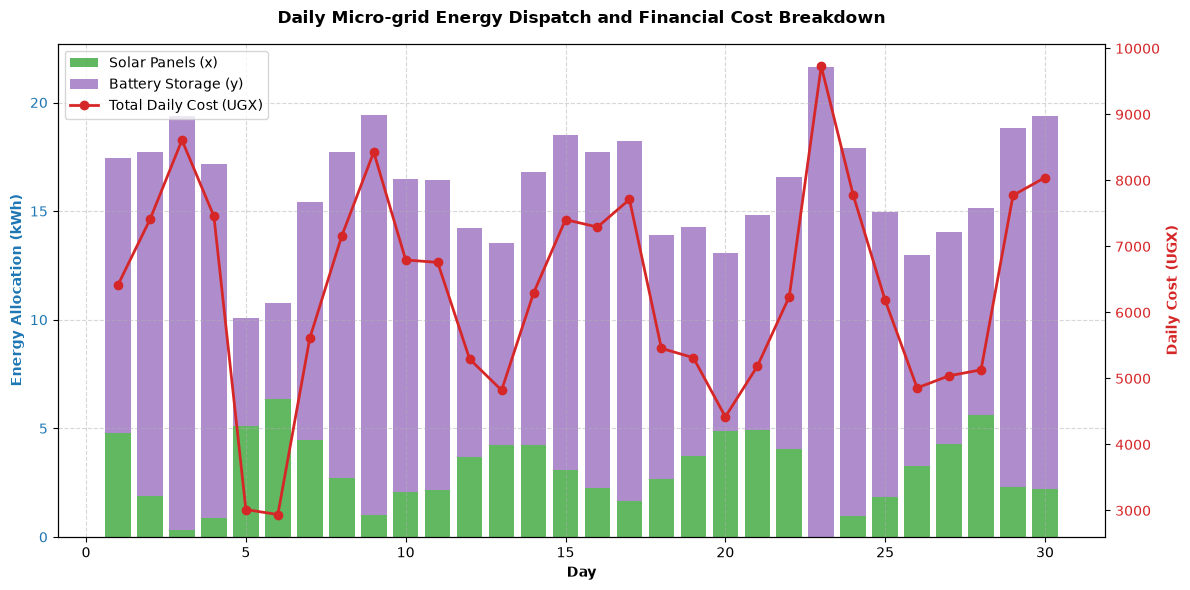

In [19]:
import matplotlib.pyplot as plt

# Create figure and primary axis for energy allocation
fig, ax1 = plt.subplots(figsize=(12, 6))

days = df_results['Day']
solar = df_results['Solar_x']
battery = df_results['Battery_y']
cost = df_results['Total_Daily_Cost_UGX']

# Stacked bar chart for energy usage
ax1.bar(days, solar, label='Solar Panels (x)', color='tab:green', alpha=0.75)
ax1.bar(days, battery, bottom=solar, label='Battery Storage (y)', color='tab:purple', alpha=0.75)

ax1.set_xlabel('Day', fontweight='bold')
ax1.set_ylabel('Energy Allocation (kWh)', color='tab:blue', fontweight='bold')
ax1.tick_params(axis='y', labelcolor='tab:blue')
ax1.grid(True, linestyle='--', alpha=0.5)

# Create secondary axis for daily financial cost
ax2 = ax1.twinx()
ax2.plot(days, cost, color='tab:red', linewidth=2.0, marker='o', label='Total Daily Cost (UGX)')
ax2.set_ylabel('Daily Cost (UGX)', color='tab:red', fontweight='bold')
ax2.tick_params(axis='y', labelcolor='tab:red')

# Combine legends from both axes into a single legend box
lines_1, labels_1 = ax1.get_legend_handles_labels()
lines_2, labels_2 = ax2.get_legend_handles_labels()
ax1.legend(lines_1 + lines_2, labels_1 + labels_2, loc='upper left')

plt.title('Daily Micro-grid Energy Dispatch and Financial Cost Breakdown', fontweight='bold', pad=15)
plt.tight_layout()
plt.show()

In [20]:
import sys
import numpy as np
import pandas as pd

# Ensure src path is accessible
project_src = r"D:\MSCS Stuff\kisomose\miniiproject 1\mini-projects-OOP\src"
if project_src not in sys.path:
    sys.path.insert(0, project_src)

from hybrid_microgrid import HybridMicroGrid

# Initialize the 3x3 hybrid micro-grid
hmg = HybridMicroGrid()

# Generate or simulate 3-load daily inputs (d1, d2, d3)
np.random.seed(42)
days = np.arange(1, 31)
d1_loads = np.clip(35.0 + 5.0 * np.sin(2 * np.pi * days / 7) + np.random.normal(0, 2.5, 30), 15.0, 60.0)
d2_loads = np.clip(25.0 + 4.0 * np.cos(2 * np.pi * days / 7) + np.random.normal(0, 2.0, 30), 10.0, 45.0)
d3_loads = np.clip(30.0 + 3.0 * np.sin(2 * np.pi * days / 14) + np.random.normal(0, 2.0, 30), 12.0, 50.0)

# Solve across all 30 days using the 3x3 system
solar_x, battery_y, diesel_z = [], [], []

for d1, d2, d3 in zip(d1_loads, d2_loads, d3_loads):
    x, y, z = hmg.solve_day_hybrid(d1, d2, d3)
    solar_x.append(max(0.0, x))  # Applying clipping for physical feasibility
    battery_y.append(max(0.0, y))
    diesel_z.append(max(0.0, z))

df_hybrid = pd.DataFrame({
    "Day": days,
    "Load_D1": np.round(d1_loads, 2),
    "Load_D2": np.round(d2_loads, 2),
    "Load_D3": np.round(d3_loads, 2),
    "Solar_x": np.round(solar_x, 2),
    "Battery_y": np.round(battery_y, 2),
    "Diesel_z": np.round(diesel_z, 2)
})

print("\n--- Hybrid Micro-Grid 3x3 Dispatch Results (First 5 Days) ---")
print(df_hybrid.head().to_string(index=False))

Hybrid MicroGrid Initialized (3x3 System)
Determinant: -16.0000
Condition Number: 6.1879

--- Hybrid Micro-Grid 3x3 Dispatch Results (First 5 Days) ---
 Day  Load_D1  Load_D2  Load_D3  Solar_x  Battery_y  Diesel_z
   1    40.15    26.29    30.34     3.39      15.74      0.00
   2    39.53    27.81    31.97     3.43      14.80      0.00
   3    38.79    21.37    30.71     2.01      17.40      0.00
   4    36.64    19.28    30.53     1.39      17.08      0.00
   5    29.54    25.76    33.97     1.92       9.83      4.13


In [22]:
import numpy as np
import pandas as pd
from scipy.linalg import solve

# 1. Select a baseline day demand from your dataset (e.g., Day 1)
d1_base = df_results.loc[0, 'Daytime_Load_D1']
d2_base = df_results.loc[0, 'Critical_Load_D2']
b_base = np.array([d1_base, d2_base], dtype=float)

# Base coefficient matrix A
A_matrix = np.array([
    [3.0, 2.0],
    [4.0, 1.0]
], dtype=float)

# Baseline solution
x_base, y_base = solve(A_matrix, b_base)

# 2. Monte Carlo Sensitivity Analysis: Perturb D1 and D2 by +/- 5% (1,000 draws)
np.random.seed(42)
num_draws = 1000

# Uniform perturbation between -5% and +5% (multiplier between 0.95 and 1.05)
d1_perturbed = d1_base * np.random.uniform(0.95, 1.05, num_draws)
d2_perturbed = d2_base * np.random.uniform(0.95, 1.05, num_draws)

# Stack into 2 x 1000 right-hand side matrix B_pert
B_pert = np.vstack([d1_perturbed, d2_perturbed])

# Solve the linear system for all 1,000 draws simultaneously (vectorized)
solutions_pert = solve(A_matrix, B_pert)
x_pert = solutions_pert[0, :]
y_pert = solutions_pert[1, :]

# 3. Calculate movement statistics (standard deviation and spread)
x_std = np.std(x_pert, ddof=1)
y_std = np.std(y_pert, ddof=1)
x_range = np.ptp(x_pert)  # peak-to-peak (max - min)
y_range = np.ptp(y_pert)

print("--- Sensitivity Analysis Report (1,000 Monte Carlo Draws) ---")
print(f"Baseline Load D1: {d1_base:.2f} | Baseline Solar x: {x_base:.2f}")
print(f"Baseline Load D2: {d2_base:.2f} | Baseline Battery y: {y_base:.2f}")
print("-" * 60)
print(f"Solar (x) Perturbed Standard Deviation: {x_std:.4f}")
print(f"Solar (x) Peak-to-Peak Variation:     {x_range:.4f}")
print(f"Battery (y) Perturbed Standard Deviation: {y_std:.4f}")
print(f"Battery (y) Peak-to-Peak Variation:     {y_range:.4f}")

# Compute and display matrix condition number relation
cond_num = np.linalg.cond(A_matrix)
print("-" * 60)
print(f"Matrix Condition Number kappa(A): {cond_num:.4f}")

--- Sensitivity Analysis Report (1,000 Monte Carlo Draws) ---
Baseline Load D1: 39.67 | Baseline Solar x: 4.78
Baseline Load D2: 31.78 | Baseline Battery y: 12.67
------------------------------------------------------------
Solar (x) Perturbed Standard Deviation: 0.4320
Solar (x) Peak-to-Peak Variation:     1.9597
Battery (y) Perturbed Standard Deviation: 1.0676
Battery (y) Peak-to-Peak Variation:     4.8240
------------------------------------------------------------
Matrix Condition Number kappa(A): 5.8284
